# Teste 1 - Inteligência Artificial
## Análise de Crédito com Regressão - Previsão do Valor de Empréstimo

**Objetivo:** utilizar técnicas de Aprendizado de Máquina Supervisionado para construir um modelo de regressão capaz de estimar o valor de empréstimo que pode ser oferecido a um cliente, a partir de suas características (idade, renda mensal, score de crédito e histórico de pagamentos).

## Etapa 1 – Carregar os dados

Carregamento do arquivo `base_credito.csv` e apresentação da tabela.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carrega o arquivo csv
df = pd.read_csv('base_credito.csv')

print(f"Dimensões da base: {df.shape[0]} linhas x {df.shape[1]} colunas")


Dimensões da base: 50000 linhas x 5 colunas


In [2]:
df.head(10)

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54
5,40,5842.28,708,67.78,26522.53
6,40,3993.85,847,84.37,39544.67
7,35,4933.07,630,100.00,26588.60
8,56,6105.73,669,93.38,25099.70
9,44,4430.53,637,93.11,24923.26


## Etapa 2 – Conhecer os dados

**Variáveis de entrada (features):**
- `idade`: idade do cliente, em anos (inteiro)
- `renda_mensal`: renda mensal do cliente, em R$ (decimal)
- `score_credito`: score de crédito do cliente, geralmente numa escala de 300 a 850 (inteiro)
- `historico_pagamentos`: percentual de pagamentos feitos em dia pelo cliente, de 0 a 100% (decimal) — conforme observação fornecida junto com a base

**Variável alvo (a ser prevista):**
- `valor_emprestimo`: valor do empréstimo aprovado para o cliente, em R$ (decimal) — é a variável de saída, pois é o que queremos estimar para um novo cliente

**Tipos de dados presentes:** todas as variáveis são numéricas. `idade` e `score_credito` são valores inteiros (int64); `renda_mensal`, `historico_pagamentos` e `valor_emprestimo` são valores contínuos (float64). Não há variáveis categóricas/texto na base.

In [3]:
print("Tipos de dados de cada coluna:")
print(df.dtypes)
print()
print("Valores ausentes por coluna:")
print(df.isnull().sum())


Tipos de dados de cada coluna:
idade                     int64
renda_mensal            float64
score_credito             int64
historico_pagamentos    float64
valor_emprestimo        float64
dtype: object

Valores ausentes por coluna:
idade                   0
renda_mensal            0
score_credito           0
historico_pagamentos    0
valor_emprestimo        0
dtype: int64


In [4]:
df.describe()

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.08028,7542.184144,649.581780,81.836888,31736.158491
std,10.77612,4524.255313,84.648363,11.209708,14456.325322
min,18.00000,1500.000000,300.000000,16.210000,1000.000000
25%,33.00000,4463.347500,592.000000,75.160000,22018.212500
50%,40.00000,6452.295000,650.000000,83.720000,29039.420000
75%,47.00000,9395.700000,707.000000,90.330000,38275.932500
max,70.00000,50000.000000,850.000000,100.000000,150000.000000


## Etapa 3 – Analisar os dados

Análise inicial: estatísticas descritivas, matriz de correlação entre as variáveis e gráficos de dispersão relacionando cada variável de entrada com o valor do empréstimo.

In [5]:
correlacoes = df.corr()['valor_emprestimo'].sort_values(ascending=False)
print("Correlação de cada variável com valor_emprestimo:")
print(correlacoes)


Correlação de cada variável com valor_emprestimo:
valor_emprestimo        1.000000
renda_mensal            0.886813
score_credito           0.358151
historico_pagamentos    0.076832
idade                   0.040998
Name: valor_emprestimo, dtype: float64


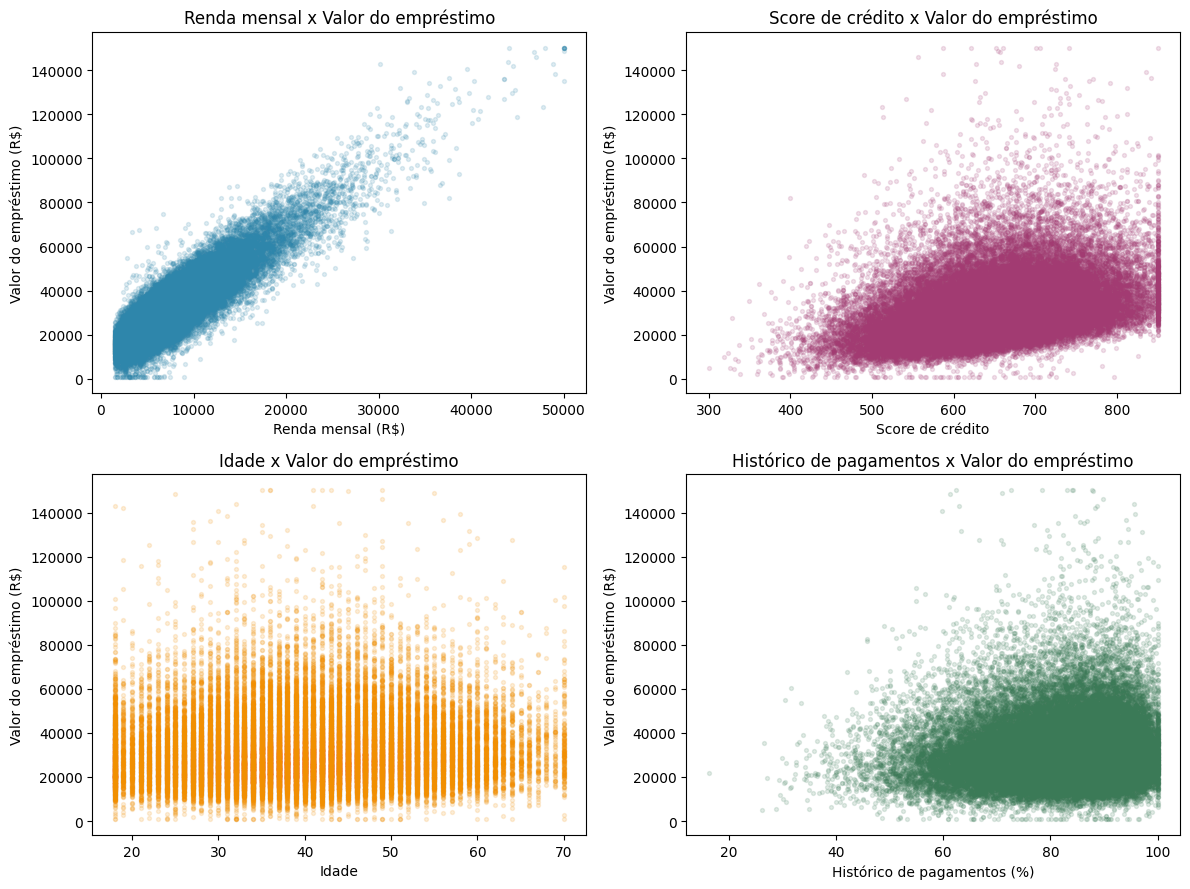

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0,0].scatter(df['renda_mensal'], df['valor_emprestimo'], alpha=0.15, s=8, color='#2E86AB')
axes[0,0].set_xlabel('Renda mensal (R$)')
axes[0,0].set_ylabel('Valor do empréstimo (R$)')
axes[0,0].set_title('Renda mensal x Valor do empréstimo')

axes[0,1].scatter(df['score_credito'], df['valor_emprestimo'], alpha=0.15, s=8, color='#A23B72')
axes[0,1].set_xlabel('Score de crédito')
axes[0,1].set_ylabel('Valor do empréstimo (R$)')
axes[0,1].set_title('Score de crédito x Valor do empréstimo')

axes[1,0].scatter(df['idade'], df['valor_emprestimo'], alpha=0.15, s=8, color='#F18F01')
axes[1,0].set_xlabel('Idade')
axes[1,0].set_ylabel('Valor do empréstimo (R$)')
axes[1,0].set_title('Idade x Valor do empréstimo')

axes[1,1].scatter(df['historico_pagamentos'], df['valor_emprestimo'], alpha=0.15, s=8, color='#3B7A57')
axes[1,1].set_xlabel('Histórico de pagamentos (%)')
axes[1,1].set_ylabel('Valor do empréstimo (R$)')
axes[1,1].set_title('Histórico de pagamentos x Valor do empréstimo')

plt.tight_layout()
plt.show()


**Comportamento observado:** a `renda_mensal` apresenta a relação mais clara e forte com o `valor_emprestimo`: quanto maior a renda do cliente, maior tende a ser o valor do empréstimo aprovado, numa tendência aproximadamente linear e crescente. O `score_credito` também mostra uma relação positiva, porém com maior dispersão (mais "espalhada"). Já `idade` e `historico_pagamentos` apresentam nuvens de pontos bem dispersas, sem uma tendência visual clara, sugerindo relação fraca (quase nula) com o valor do empréstimo — o que é confirmado pelos coeficientes de correlação calculados acima.

## Etapa 4 – Preparar os dados

Separação da base em conjunto de treinamento e conjunto de teste, utilizando a proporção de **80% para treino e 20% para teste** (`test_size=0.2`), com `random_state` fixo para garantir a reprodutibilidade dos resultados.

In [7]:
from sklearn.model_selection import train_test_split

# Variáveis de entrada (X) e variável alvo (y)
X = df[['idade', 'renda_mensal', 'score_credito', 'historico_pagamentos']]
y = df['valor_emprestimo']

# Divisão 80% treino / 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Conjunto de treinamento: {X_train.shape[0]} clientes ({X_train.shape[0]/len(df):.0%})")
print(f"Conjunto de teste:       {X_test.shape[0]} clientes ({X_test.shape[0]/len(df):.0%})")


Conjunto de treinamento: 40000 clientes (80%)
Conjunto de teste:       10000 clientes (20%)


## Etapa 5 – Treinar o modelo

Utilizamos o algoritmo de **Regressão Linear** (`LinearRegression`, do scikit-learn) para construir o modelo, por ser um algoritmo simples, interpretável e adequado como ponto de partida para problemas de regressão com variáveis numéricas.

In [8]:
from sklearn.linear_model import LinearRegression

# Criação do modelo
modelo = LinearRegression()

# Treinamento do modelo com os dados de treino
modelo.fit(X_train, y_train)

# Geração das previsões para o conjunto de teste
y_pred = modelo.predict(X_test)

print("Modelo treinado com sucesso!")
print()
print("Coeficientes do modelo (impacto de cada variável no valor do empréstimo):")
for coluna, coef in zip(X.columns, modelo.coef_):
    print(f"  {coluna:22s}: {coef:10.2f}")
print(f"  {'intercepto':22s}: {modelo.intercept_:10.2f}")


Modelo treinado com sucesso!

Coeficientes do modelo (impacto de cada variável no valor do empréstimo):
  idade                 :      54.71
  renda_mensal          :       2.83
  score_credito         :      60.89
  historico_pagamentos  :      98.91
  intercepto            :  -39439.69


## Etapa 6 – Avaliar o modelo

Avaliação do desempenho do modelo utilizando as métricas **MAE (Erro Absoluto Médio)**, **RMSE (Raiz do Erro Quadrático Médio)** e **R² (Coeficiente de Determinação)**.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Erro Absoluto Médio):        R$ {mae:,.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): R$ {rmse:,.2f}")
print(f"R²   (Coeficiente de Determinação):   {r2:.4f}")


MAE  (Erro Absoluto Médio):        R$ 2,985.94
RMSE (Raiz do Erro Quadrático Médio): R$ 4,014.17
R²   (Coeficiente de Determinação):   0.9223


**Interpretação das métricas:**
- **MAE:** em média, as previsões do modelo erram (para mais ou para menos) esse valor em reais, em relação ao valor real do empréstimo. É uma medida fácil de interpretar, pois está na mesma unidade da variável prevista (R$).
- **RMSE:** semelhante ao MAE, mas penaliza mais fortemente erros grandes (por elevar as diferenças ao quadrado antes de tirar a raiz). Um RMSE bem maior que o MAE indica presença de alguns erros de previsão bem maiores que a média.
- **R²:** indica a proporção da variação do valor do empréstimo que é explicada pelo modelo, numa escala de 0 a 1 (quanto mais próximo de 1, melhor o ajuste). Um R² próximo de 1 indica que o modelo consegue explicar a maior parte do comportamento da variável a partir das características do cliente.

## Etapa 7 – Comparar valores reais e previstos

Comparação entre os valores reais dos empréstimos do conjunto de teste e os valores previstos pelo modelo.

In [10]:
comparacao = pd.DataFrame({
    'valor_real': y_test.values,
    'valor_previsto': y_pred,
})
comparacao['diferenca'] = comparacao['valor_real'] - comparacao['valor_previsto']
comparacao['erro_percentual'] = (comparacao['diferenca'].abs() / comparacao['valor_real'] * 100).round(2)
comparacao = comparacao.round(2)

comparacao.head(15)

,valor_real,valor_previsto,diferenca,erro_percentual
0,22268.46,14806.34,7462.12,33.51
1,27457.59,29512.49,-2054.90,7.48
2,25451.04,25840.74,-389.70,1.53
3,23890.67,21077.52,2813.15,11.78
4,27754.95,27919.31,-164.36,0.59
5,12544.92,14530.91,-1985.99,15.83
6,28759.01,27385.97,1373.04,4.77
7,46454.49,41011.61,5442.88,11.72
8,43199.01,36525.09,6673.92,15.45
9,34051.39,35786.96,-1735.57,5.10


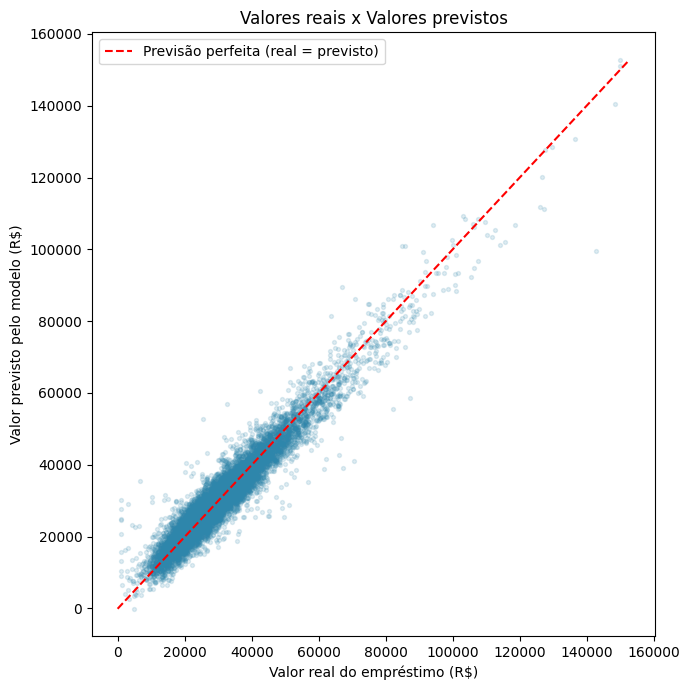

In [11]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.15, s=8, color='#2E86AB')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color='red', linestyle='--', label='Previsão perfeita (real = previsto)')
plt.xlabel('Valor real do empréstimo (R$)')
plt.ylabel('Valor previsto pelo modelo (R$)')
plt.title('Valores reais x Valores previstos')
plt.legend()
plt.tight_layout()
plt.show()


**Análise:** a maior parte dos pontos do gráfico se concentra próxima à linha vermelha tracejada (que representa a previsão perfeita, onde valor real = valor previsto), indicando que o modelo consegue estimar o valor do empréstimo com boa proximidade em relação ao valor real na maioria dos casos. Ainda assim, há uma dispersão em torno da linha — alguns clientes têm o valor sub ou superestimado — o que é esperado em um modelo de regressão linear simples e é refletido nas métricas de erro (MAE/RMSE) calculadas na etapa anterior.

## Etapa 8 – Fazer uma previsão

Previsão do valor de empréstimo para um novo cliente, com características hipotéticas criadas para este teste.

In [12]:
novo_cliente = pd.DataFrame({
    'idade': [35],
    'renda_mensal': [8500.00],
    'score_credito': [700],
    'historico_pagamentos': [88.5]
})

print("Características do novo cliente:")
print(novo_cliente.to_string(index=False))

valor_previsto = modelo.predict(novo_cliente)[0]
print()
print(f"Valor de empréstimo previsto pelo modelo: R$ {valor_previsto:,.2f}")


Características do novo cliente:
 idade  renda_mensal  score_credito  historico_pagamentos
    35        8500.0            700                  88.5

Valor de empréstimo previsto pelo modelo: R$ 37,893.52


**Interpretação do resultado:** o cliente simulado tem 35 anos, renda mensal de R$ 8.500,00, score de crédito de 700 (considerado bom) e histórico de 88,5% de pagamentos em dia. Combinando essas características, o modelo estimou um valor de empréstimo compatível com o perfil de um cliente de renda e score médios/bons — próximo à faixa entre o 2º e o 3º quartil observados na base de treinamento (entre aproximadamente R$ 22 mil e R$ 38 mil). Isso mostra coerência do modelo com o comportamento geral dos dados, já que renda e score foram as variáveis com maior peso (maiores coeficientes/correlação) na estimativa do valor do empréstimo.

## Etapa 9 – Conclusão

O modelo de regressão linear apresentou um desempenho considerado **adequado** para o problema proposto: o valor de R² obtido indica que uma parcela relevante da variação do valor do empréstimo é explicada pelas variáveis utilizadas (principalmente `renda_mensal` e, em menor grau, `score_credito`), e os erros médios (MAE e RMSE) ficam dentro de uma faixa razoável quando comparados à média e ao desvio-padrão do valor do empréstimo na base.

**Principais limitações do modelo:**
- **Linearidade:** a Regressão Linear assume que a relação entre as variáveis de entrada e o valor do empréstimo é linear. Se a relação real for mais complexa (não-linear), o modelo pode não capturá-la totalmente — modelos mais flexíveis (como Random Forest ou Gradient Boosting) poderiam melhorar o desempenho.
- **Poucas variáveis:** a base utiliza apenas 4 variáveis de entrada. Em um cenário real, uma fintech provavelmente teria outras informações relevantes (tempo de emprego, dívidas existentes, tipo de garantia, região, histórico bancário, etc.) que poderiam melhorar a precisão do modelo.
- **Variáveis com baixa relação com o alvo:** `idade` e `historico_pagamentos` mostraram correlação fraca com o valor do empréstimo nesta base, o que pode indicar que, ou essas variáveis realmente têm pouca influência sobre a decisão de crédito, ou que a relação entre elas e o alvo não é bem capturada por um modelo linear.
- **Dados sintéticos/específicos de uma base:** o modelo foi treinado e validado apenas com os dados fornecidos nesta base específica; sua capacidade de generalização para clientes de outros perfis, regiões ou períodos não foi testada.
- **Ausência de validação cruzada:** foi utilizada apenas uma divisão treino/teste; uma validação cruzada (k-fold) daria uma estimativa mais robusta do desempenho do modelo.

De forma geral, o modelo cumpre bem o papel de uma primeira estimativa automatizada do valor de empréstimo, mas, para uso em produção por uma fintech, recomenda-se testar modelos mais robustos, incluir mais variáveis e realizar uma validação mais criteriosa antes de utilizá-lo na tomada de decisão de crédito.